# Предсказание калорийности блюд

Цель работы — обучить модель, которая по фотографии и списку ингредиентов предсказывает общую калорийность порции. Задача относится к регрессии. Требуемое качество — **MAE < 50 ккал** на тестовой выборке.

Работа состоит из анализа данных, подготовки пайплайна, обучения модели и разбора ошибок. Для выбора параметров использую валидационную часть train; официальный test оставляю для итоговой оценки.

## 1. Окружение

Для обучения используется RTX 4060 Ti. Сначала проверю версию PyTorch и доступность CUDA, затем загружу конфигурацию эксперимента. В `configs/main.yaml` указаны архитектура, размер батча, learning rate и путь сохранения модели.

In [14]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer
from IPython.display import display, Markdown, Image as DisplayImage

ROOT = Path.cwd()
if not (ROOT / "scripts").is_dir():
    raise RuntimeError("Откройте notebook.ipynb из корня проекта calorie_prediction")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.config import load_config
from scripts.data import prepare_data
from scripts.eda import run_eda
from scripts.baselines import evaluate_baselines
from scripts.experiments import run_or_load, compare_validation_runs, plot_history
from scripts.evaluate import evaluate_checkpoint, load_predictor, predict_one
from scripts.export_model import export_model

CONFIG_PATH = "configs/main.yaml"
cfg = load_config(CONFIG_PATH)
pd.set_option("display.max_colwidth", 100)
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Configuration:", CONFIG_PATH)
print("Main inputs: photo + ingredient names; use_mass =", cfg.use_mass)

Python: c:\ml_projects_mifi\calorie_prediction\.venv\Scripts\python.exe
PyTorch: 2.10.0+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Ti
Configuration: configs/main.yaml
Main inputs: photo + ingredient names; use_mass = False


## 2. Загрузка и объединение таблиц

В таблице блюд ингредиенты записаны техническими ID. Например, `ingr_0000000122` соответствует ключу 122 в справочнике. Заменю такие ID названиями продуктов, чтобы текстовая модель получала осмысленный состав.

Одновременно проверю уникальность блюд, наличие изображений и корректность целевой переменной. Фотография каждого блюда находится в `data/images/<dish_id>/rgb.png`.

Из официального train выделю валидационную выборку. При разделении одинаковые фотографии, если они встретятся, должны оставаться в одной группе.

In [15]:
frame, ingredient_dictionary, splits = prepare_data(cfg)
print("Блюда:", len(frame), "Справочник ингредиентов:", len(ingredient_dictionary))
print("Разбиение:", {name: len(part) for name, part in splits.items()})
display(ingredient_dictionary[["id", "ingr"]].head())
display(frame[["dish_id", "ingredients", "ingredients_text", "total_calories", "split"]].head())

Image audit: 1000/3262
Image audit: 2000/3262
Image audit: 3000/3262
Блюда: 3262 Справочник ингредиентов: 555
Разбиение: {'train': 2204, 'val': 551, 'test': 507}


,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes


,dish_id,ingredients,ingredients_text,total_calories,split
0,dish_1561662216,ingr_0000000508;ingr_0000000122;ingr_0000000026;ingr_0000000524;ingr_0000000094;ingr_0000000023;...,"apple, bok choy, brown rice, garlic, lemon juice, millet, mixed greens, olive oil, onions, parsl...",300.794281,test
1,dish_1561662054,ingr_0000000312;ingr_0000000026;ingr_0000000029;ingr_0000000122;ingr_0000000508;ingr_0000000513;...,"apple, bok choy, garlic, green beans, lemon juice, millet, mixed greens, olive oil, onions, pars...",419.438782,train
2,dish_1562008979,ingr_0000000448;ingr_0000000520;ingr_0000000462;ingr_0000000514;ingr_0000000152;ingr_0000000312;...,"cabbage, caesar salad, carrot, garlic, jalapenos, lemon juice, mayonnaise, olive oil, parsley, p...",382.936646,test
3,dish_1560455030,ingr_0000000471;ingr_0000000031;ingr_0000000347,"baby carrots, cherry tomatoes, cucumbers",20.590000,train
4,dish_1558372433,ingr_0000000453,deprecated,74.360001,train


## 3. Проверка данных

Посмотрю на размер выборок, пропуски и распределение калорийности. Основные графики строю по обучающей части. Большие значения не удаляю автоматически: они могут соответствовать большой порции, а не ошибке разметки.

,total_calories,total_mass,n_ingredients
count,3262.000000,3262.000000,3262.000000
mean,255.012738,214.980074,7.313305
std,219.637570,161.497428,6.943276
min,0.000000,1.000000,1.000000
25%,80.114996,92.000000,1.000000
50%,209.110062,177.000000,4.000000
75%,375.122963,305.000000,12.000000
max,3943.325195,3051.000000,34.000000


,split,n,calories_mean,calories_median,mass_median
0,test,507,255.467051,226.014999,161.0
1,train,2755,254.929131,208.115997,179.0


Пропуски: {'total_calories': 0, 'total_mass': 0, 'ingredients': 0}
Точные дубликаты фото: 0
Размеры фото: [{'width': 640, 'height': 480, 'n': 3262}]


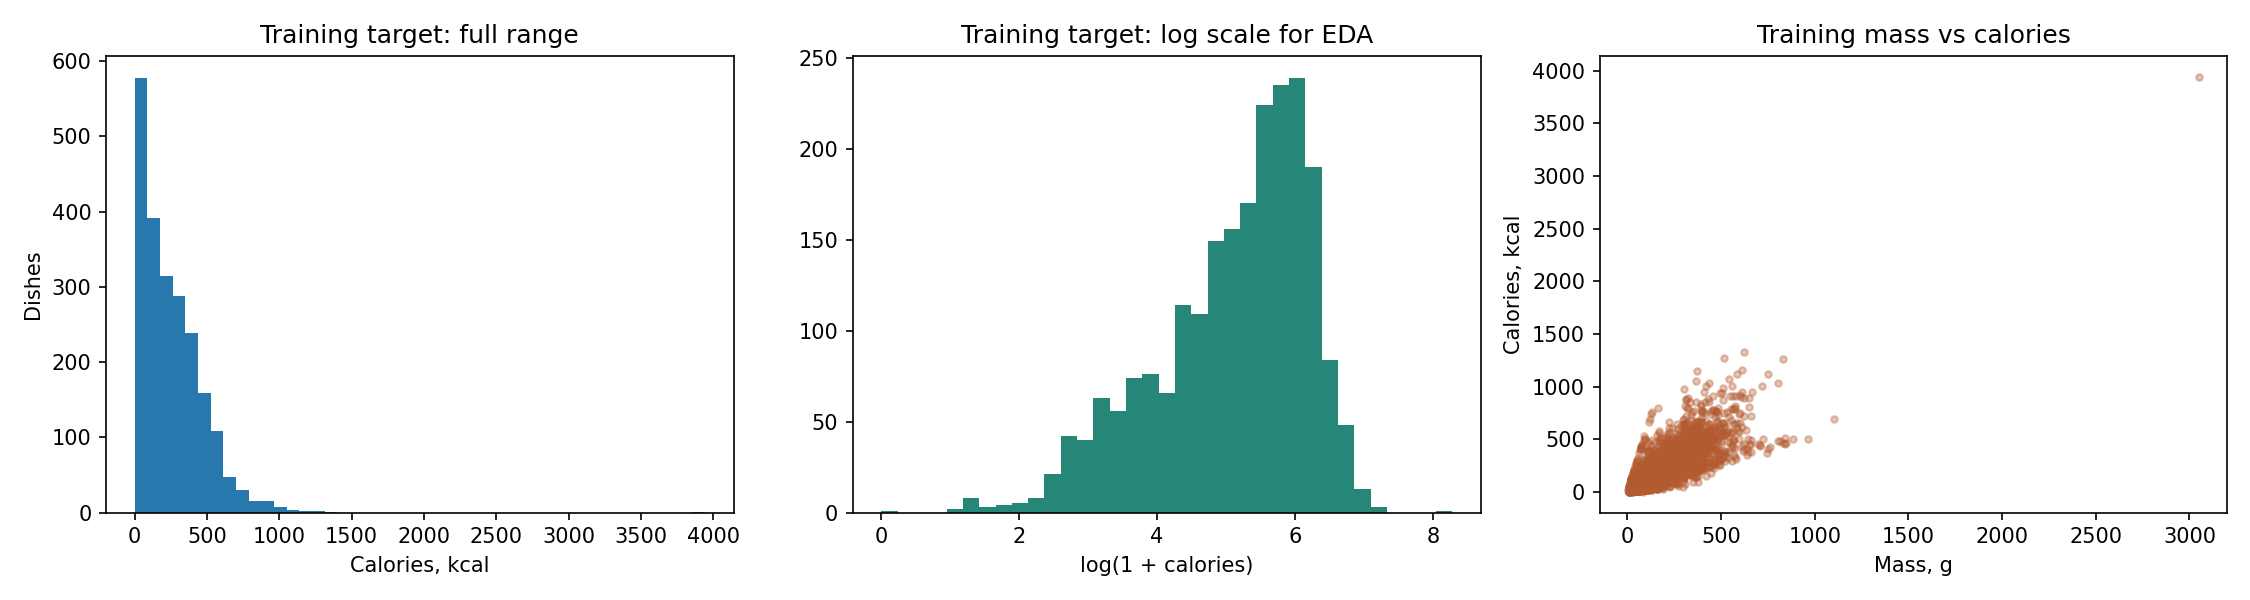

In [16]:
summary = run_eda(frame, ingredient_dictionary, splits, ROOT / "reports/eda")
display(frame[["total_calories", "total_mass", "n_ingredients"]].describe())
display(pd.read_csv(ROOT / "reports/eda/split_summary.csv"))
print("Пропуски:", summary["missing_source_values"])
print("Точные дубликаты фото:", summary["duplicate_images"])
print("Размеры фото:", summary["image_sizes"])
display(DisplayImage(filename=str(ROOT / "reports/eda/distributions.png"), width=1100))

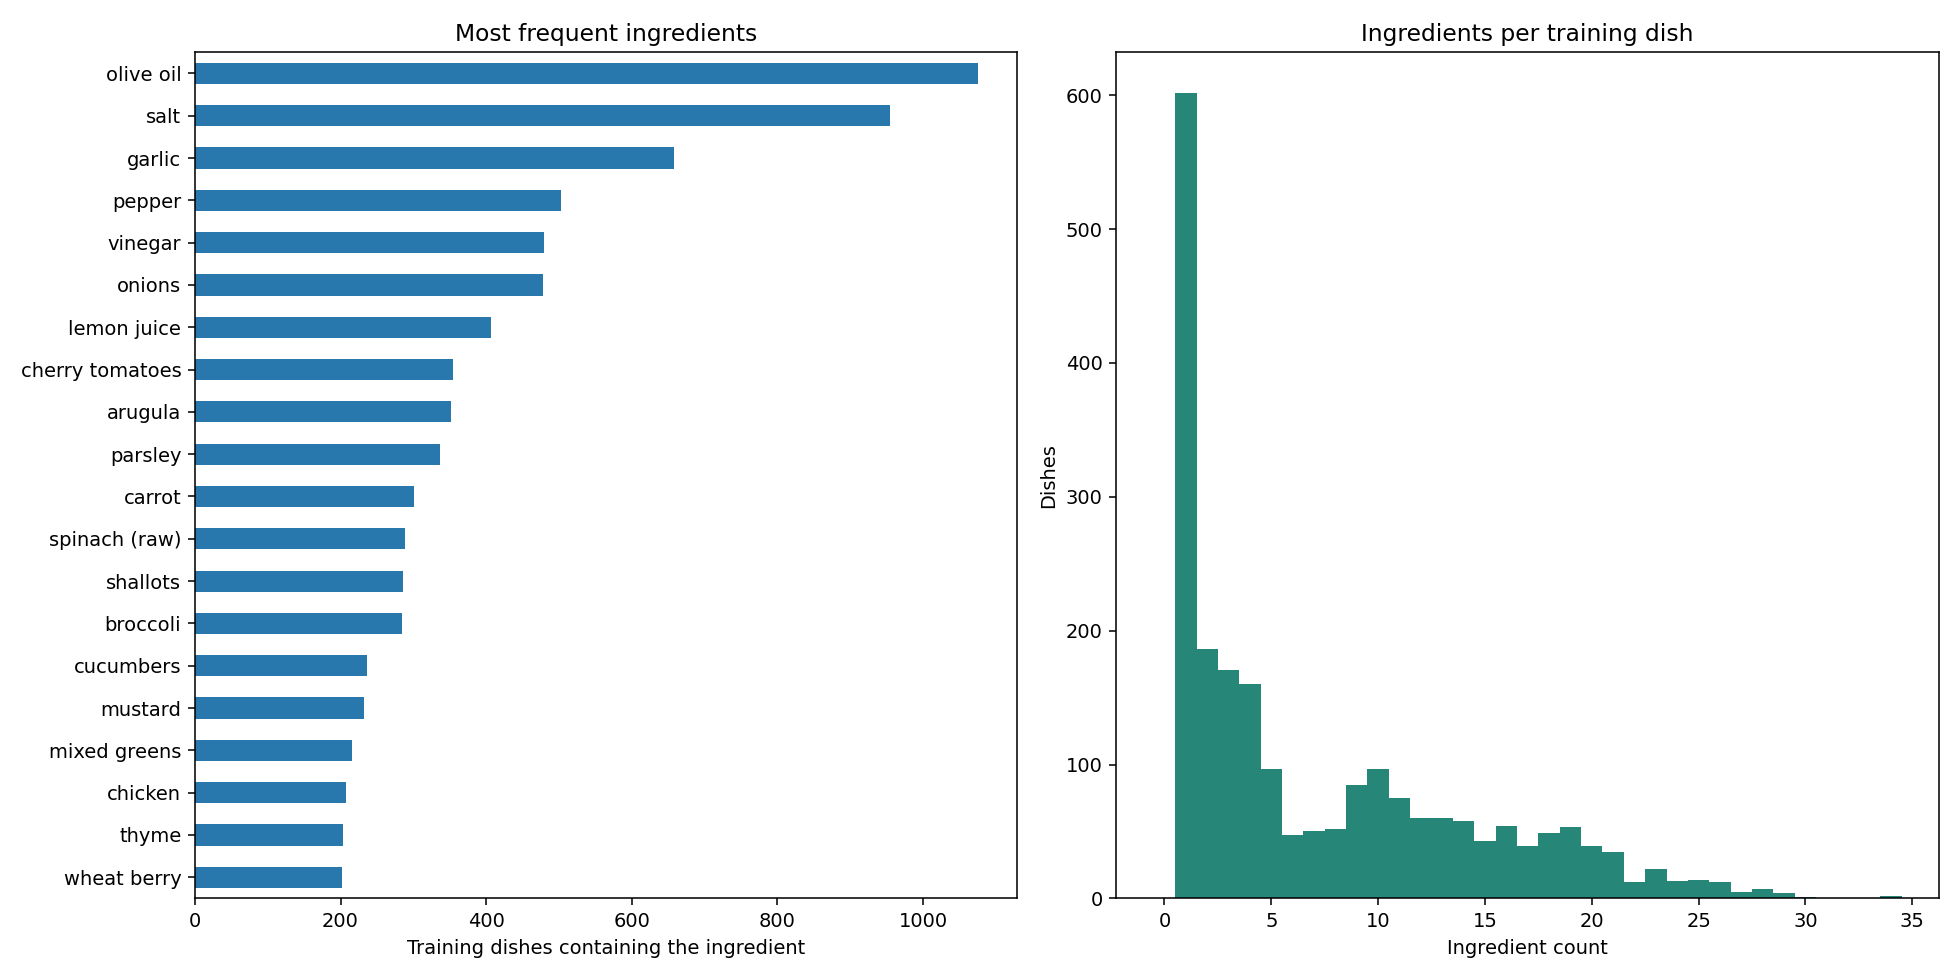

Блюда с нулевым target:


,dish_id,ingredients_text,total_mass,split
0,dish_1557861216,plate only,1.0,test
1,dish_1556575700,plate only,86.0,train


Наибольшие target (не удаляются автоматически):


,dish_id,total_calories,total_mass,split,ingredients_text
0,dish_1560974769,3943.325195,3051.0,train,"black beans, cheese, cherry tomatoes, chili, corn, garlic, lime, onions, salt, sour cream, spina..."
1,dish_1565033265,1324.084961,625.0,train,"broccoli, chicken, mixed greens, olive oil, olives, vinaigrette"
2,dish_1562603895,1268.157349,517.0,train,"blackberries, granola, hash browns, mixed greens, raspberries, sausage, scrambled eggs, vinaigrette"
3,dish_1564170010,1264.548340,831.0,train,"arugula, broccoli, brown rice, cheese, chicken thighs, chili, cilantro, cucumbers, garlic, kale,..."
4,dish_1563476577,1238.033691,857.0,train,"apple, beef, broccoli, brown rice, brownies, cheese pizza, chili, cilantro, cranberries, cream, ..."


In [17]:
display(DisplayImage(filename=str(ROOT / "reports/eda/ingredients.png"), width=1000))
print("Блюда с нулевым target:")
display(pd.read_csv(ROOT / "reports/eda/zero_calorie_dishes.csv"))
print("Наибольшие target (не удаляются автоматически):")
display(pd.read_csv(ROOT / "reports/eda/largest_targets.csv").head())

In [18]:
from collections import Counter

ingredient_counts = Counter(
    ingredient
    for ingredients in splits["train"]["ingredient_names"]
    for ingredient in set(ingredients)
)

display(pd.Series({
    "Всего блюд": len(frame),
    "Train": len(splits["train"]),
    "Validation": len(splits["val"]),
    "Test": len(splits["test"]),
    "Медиана калорийности": frame["total_calories"].median(),
    "Максимальная калорийность": frame["total_calories"].max(),
    "Нулевая калорийность": frame["total_calories"].eq(0).sum(),
    "Максимальная длина текста": lengths.max(),
    "Лимит токенов": cfg.max_length,
    "Обрезанных описаний": (lengths > cfg.max_length).sum(),
    "Редких ингредиентов": sum(
        count <= 5 for count in ingredient_counts.values()
    ),
}))

Всего блюд                   3262.000000
Train                        2204.000000
Validation                    551.000000
Test                          507.000000
Медиана калорийности          209.110062
Максимальная калорийность    3943.325195
Нулевая калорийность            2.000000
Максимальная длина текста     103.000000
Лимит токенов                 128.000000
Обрезанных описаний             0.000000
Редких ингредиентов            33.000000
dtype: float64

## 4. Примеры фотографий

На примерах есть как отдельные продукты, так и сложные блюда. Список ингредиентов описывает состав, но не количество каждого продукта. Фотография может дать дополнительную информацию о размере порции.

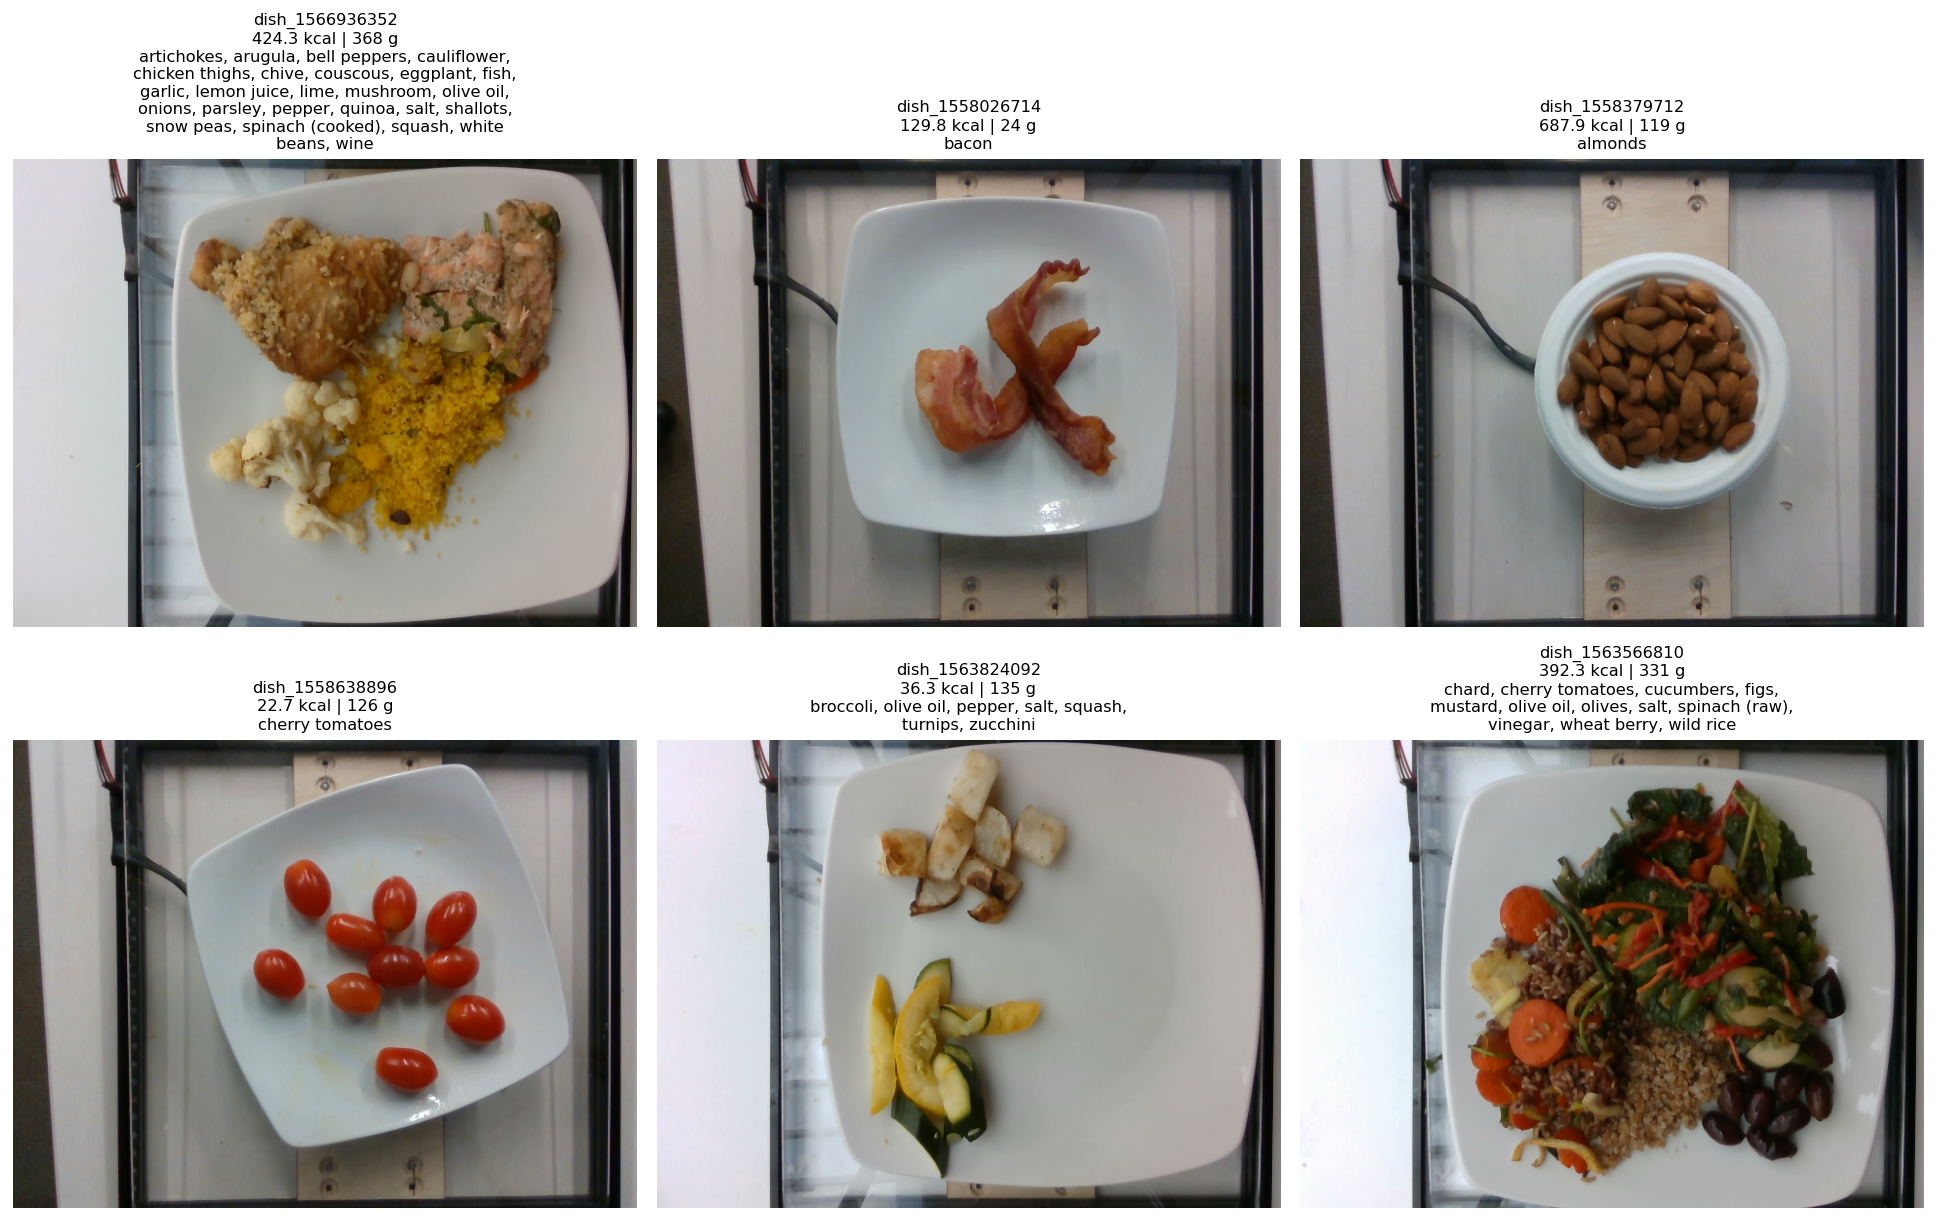

In [19]:
display(DisplayImage(filename=str(ROOT / "reports/eda/sample_dishes.png"), width=1100))

## 5. Длина текстовых описаний

Токенизатор разбивает названия продуктов на токены. Проверю длины описаний на train, чтобы выбрать достаточный `max_length` и не потерять конец списка ингредиентов.

In [20]:
tokenizer = AutoTokenizer.from_pretrained(cfg.text_model)
lengths = np.array([len(ids) for ids in tokenizer(splits["train"]["ingredients_text"].tolist(),
                                                 truncation=False)["input_ids"]])
text_statistics = {
    "train_texts": int(len(lengths)),
    "max_tokens": int(lengths.max()),
    "p95_tokens": float(np.quantile(lengths, 0.95)),
    "truncated_at_config_max_length": int((lengths > cfg.max_length).sum()),
}
print(text_statistics)
(ROOT / "reports/eda/token_lengths.json").write_text(json.dumps(text_statistics, indent=2), encoding="utf-8");

{'train_texts': 2204, 'max_tokens': 103, 'p95_tokens': 62.0, 'truncated_at_config_max_length': 0}


## 6. Выводы по данным

В наборе 3 262 блюда. Для обучения выделено 2 204, для валидации — 551, для тестирования — 507. Пропуски в исходных таблицах и точные дубликаты фотографий не обнаружены.

Распределение калорийности имеет длинный правый хвост: медиана составляет около 209 ккал, а максимум — около 3 943 ккал. Есть два нулевых значения. Это одна из причин не использовать MAPE; основной метрикой остается MAE.

На train максимальная длина текста составила 103 токена. При `max_length=128` описания не обрезаются. В этой части данных также есть 33 ингредиента, встречающихся не более пяти раз: на них модели может не хватать примеров.

Для решения выбраны предобученные ResNet18 и DistilBERT. Датасет небольшой, поэтому обучение обоих энкодеров с нуля было бы затруднительно. Признаки изображения и текста будут объединяться перед регрессионной головой.

Аугментации должны сохранять содержимое блюда. Использую отражение, повороты на 90° и небольшое изменение цвета. Обрезку значительной части фотографии исключаю: после нее target уже не обязательно соответствует видимой еде.

Масса связана с калорийностью, но в основную модель не передается: в исходной постановке доступны только фотография и ингредиенты.

In [22]:
display(Markdown((ROOT / "reports/eda/EDA_REPORT.md").read_text(encoding="utf-8")))

# Исследовательский анализ данных

В данных 3262 блюд и 555 записей справочника ингредиентов.
Официальный train: 2755, test: 507.
Внутри официального train: обучение — 2204, валидация — 551.
Разбиение фиксировано seed=42; одинаковые фотографии объединяются в одну группу.

Медиана калорийности по исходному набору: 209.11 ккал;
минимум — 0.00, максимум — 3943.33 ккал.
Блюд с нулевой целевой калорийностью: 2.
Точных повторов фотографий: 0.
Все указанные в таблице изображения прочитаны; все ID ингредиентов переведены в названия.

В обучающей части коэффициент корреляции массы с калорийностью равен
0.777. Корреляция сама по себе не доказывает причинность
и не позволяет восстановить калорийность без знания состава. Масса не поступает в основную модель.
Ингредиентов, встречающихся не более чем в пяти обучающих блюдах: 33.

## Промежуточные выводы

1. Решается регрессия общей калорийности порции, а не ккал на 100 г.
2. ID ингредиентов заменены именами. Текст нормализован и отсортирован; справочник не содержит target.
3. Используется перенос обучения: ResNet18 для изображения и DistilBERT для английских названий.
4. Умеренные изменения цвета, отражение и повороты на 90° сохраняют состав блюда.
   Агрессивные обрезки и удаление участков изображения исключены: калорийность оставшейся части неизвестна.
5. Главный критерий — MAE в ккал. Дополнительно измеряются RMSE, R², медиана и 90-й перцентиль ошибки.
6. Нулевые значения и большие порции не удаляются автоматически. Их списки сохранены для проверки.
7. Все решения по модели и остановке обучения принимаются по validation; test не участвует в подборе.


## Следующий этап

На основе анализа выбран подход с объединением признаков фотографии и текста.
Его качество будет оцениваться после обучения по MAE на официальном test.


## 7. Простые модели для сравнения

Начну с двух ориентиров. Первый всегда предсказывает медиану обучающей выборки — оптимальную константу для MAE. Второй использует TF-IDF и Ridge по названиям ингредиентов.

Векторизатор и регрессия обучаются только на train. Три значения регуляризации сравниваются на validation.

In [23]:
baseline_table = evaluate_baselines(splits, ROOT / "reports/eda")
display(baseline_table)
best_text = baseline_table.loc[baseline_table["model"].str.startswith("tfidf")].iloc[0]
median_row = baseline_table.loc[baseline_table["model"].eq("train_median")].iloc[0]
display(Markdown(f"Медианный baseline: **{median_row.mae:.2f} ккал MAE**. "
                 f"Лучший текстовый baseline: **{best_text.mae:.2f} ккал** на validation. "
                 "Это исходные ориентиры; они не являются результатом DL-модели или финального test."))

,model,n,mae,rmse,r2,median_ae,p90_ae,bias,negative_predictions
0,tfidf_ridge_alpha_1,551,93.728654,141.786421,0.541854,63.520486,209.497649,4.447941,0
1,tfidf_ridge_alpha_10,551,121.119906,157.819814,0.432380,98.827872,229.864838,4.590876,0
2,tfidf_ridge_alpha_100,551,153.301460,191.652538,0.162925,142.402743,274.563423,5.581713,0
3,train_median,551,164.035235,212.795745,-0.031955,138.828071,335.094925,-37.445840,0


Медианный baseline: **164.04 ккал MAE**. Лучший текстовый baseline: **93.73 ккал** на validation. Это исходные ориентиры; они не являются результатом DL-модели или финального test.

## 8. Обучение нейросети

У модели две ветви: ResNet18 извлекает признаки изображения, DistilBERT — признаки текста. После объединения векторов полносвязная сеть возвращает одно число. Последний слой — `Linear(..., 1)` без активации; функция потерь — L1.


Функция `run_or_load()` запускает обучение через `train()`, если сохраненной модели нет. Параметр `RESUME_TRAINING` позволяет продолжить прерванный запуск.

In [24]:
assert torch.cuda.is_available(), "Для обучения выберите CUDA-окружение по START_HERE.md"
assert not cfg.use_mass, "Основной ноутбук сравнивает модели только с фото и ингредиентами"
RESUME_TRAINING = False
training_result = run_or_load(CONFIG_PATH, resume=RESUME_TRAINING)
print(training_result)

Image audit: 1000/3262
Image audit: 2000/3262
Image audit: 3000/3262


'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: c2c3e1d2-4a57-41c8-b85a-7eacfbd1c233)')' thrown while requesting HEAD https://huggingface.co/distilbert/distilbert-base-uncased/resolve/main/tokenizer_config.json
Retrying in 1s [Retry 1/5].
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Device: cuda | train=2204, val=551, test=507
Effective batch: 16 | use_mass=False
NVIDIA GeForce RTX 4060 Ti
Epoch 1/25 | head warm-up | trainable=460,801
  batch 100/551 | train MAE so far 150.961 kcal
  batch 200/551 | train MAE so far 134.174 kcal
  batch 300/551 | train MAE so far 118.510 kcal
  batch 400/551 | train MAE so far 111.518 kcal
  batch 500/551 | train MAE so far 107.649 kcal
  batch 551/551 | train MAE so far 105.075 kcal
  train MAE=105.075 | val MAE=82.059 | best=82.059 | 47.4s
Epoch 2/25 | head warm-up | trainable=460,801
  batch 100/551 | train MAE so far 89.929 kcal
  batch 200/551 | train MAE so far 91.445 kcal
  batch 300/551 | train MAE so far 93.234 kcal
  batch 400/551 | train MAE so far 94.136 kcal
  batch 500/551 | train MAE so far 93.525 kcal
  batch 551/551 | train MAE so far 93.595 kcal
  train MAE=93.595 | val MAE=103.576 | best=82.059 | 44.4s
Epoch 3/25 | fine-tuning | trainable=25,813,057
  batch 100/551 | train MAE so far 79.526 kcal
  batch 200/551 

## 9. Динамика обучения

По графикам сравню изменение ошибки на train и validation. Train MAE считается с аугментациями и dropout, а validation MAE — без них. Поэтому различие между линиями нужно оценивать вместе с общей динамикой. Для дальнейшей проверки используется эпоха с минимальной validation MAE.

,epoch,train_mae,val_mae,val_rmse,seconds,peak_gpu_gb
0,1,105.075373,82.058856,123.253956,47.387501,0.385627
1,2,93.594638,103.575766,154.367592,44.405901,0.385627
2,3,81.314077,73.861023,117.554016,46.528205,0.802628
3,4,72.447191,62.242229,94.076513,46.534325,0.802628
4,5,68.395686,65.363257,104.337420,46.355229,0.802628
5,6,64.536861,67.130513,106.578403,46.064343,0.802628
6,7,62.218524,63.833266,90.356724,46.073675,0.802628
7,8,58.175288,52.587310,82.270336,46.109801,0.802628
8,9,53.396845,50.277539,78.019088,45.841464,0.802628
9,10,52.305994,47.818164,73.974221,45.853161,0.802628


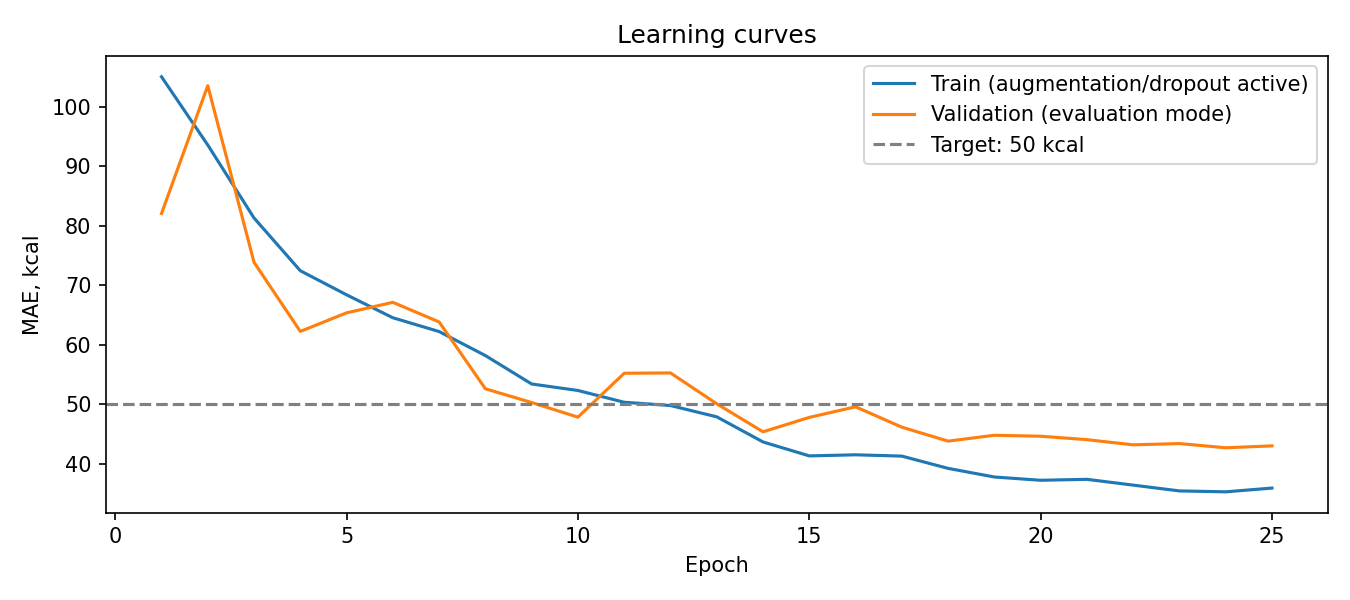

In [25]:
history = plot_history(cfg.run_dir, ROOT / "reports" / Path(cfg.run_dir).name / "learning_curves.png")
display(history[["epoch", "train_mae", "val_mae", "val_rmse", "seconds", "peak_gpu_gb"]])
display(DisplayImage(filename=str(ROOT / "reports" / Path(cfg.run_dir).name / "learning_curves.png"), width=900))

## 10. Сравнение экспериментов


In [26]:
EXTRA_CONFIGS = []  # Например: ["configs/resnet50.yaml"]
for config_path in EXTRA_CONFIGS:
    run_or_load(config_path)

comparison = compare_validation_runs([CONFIG_PATH] + EXTRA_CONFIGS)
display(comparison)
comparison.to_csv(ROOT / "reports/validation_comparison.csv", index=False)
selected_config = load_config(comparison.iloc[0]["config"])
selected_checkpoint = selected_config.path(selected_config.run_dir) / "best.pt"
print("Выбрана модель по минимальной validation MAE:", selected_checkpoint)

,config,run_dir,image_model,val_mae,val_rmse
0,configs/main.yaml,artifacts/main,resnet18.a1_in1k,42.669276,67.957539


Выбрана модель по минимальной validation MAE: C:\ml_projects_mifi\calorie_prediction\artifacts\main\best.pt


## 11. Проверка на тестовой выборке

Загружу модель, выбранную по валидации, и рассчитаю метрики на всем официальном test. Основной результат — MAE в ккал. Дополнительно посмотрю на RMSE, R² и распределение ошибок. Порог задания проверяется строго: `MAE < 50`.

Image audit: 1000/3262
Image audit: 2000/3262
Image audit: 3000/3262
{
  "n": 507,
  "mae": 49.7429775907208,
  "rmse": 77.77339367989518,
  "r2": 0.8654578946219954,
  "median_ae": 29.9029541015625,
  "p90_ae": 118.60701904296877,
  "bias": -10.783501406628234,
  "negative_predictions": 4,
  "target_met": true,
  "use_mass": false,
  "best_epoch": 24,
  "checkpoint_sha256": "aadc5556ae467d5a337b42b180960ceeeaf6eb0b33faafdca75ff30e8f216d82",
  "checkpoint_selection": "minimum validation MAE",
  "subset": "official test"
}


,n,mae,rmse,r2,median_ae,p90_ae,bias,negative_predictions,target_met,use_mass,best_epoch,checkpoint_sha256,checkpoint_selection,subset
0,507,49.742978,77.773394,0.865458,29.902954,118.607019,-10.783501,4,True,False,24,aadc5556ae467d5a337b42b180960ceeeaf6eb0b33faafdca75ff30e8f216d82,minimum validation MAE,official test


**Test MAE = 49.743 ккал. Порог < 50 достигнут.**

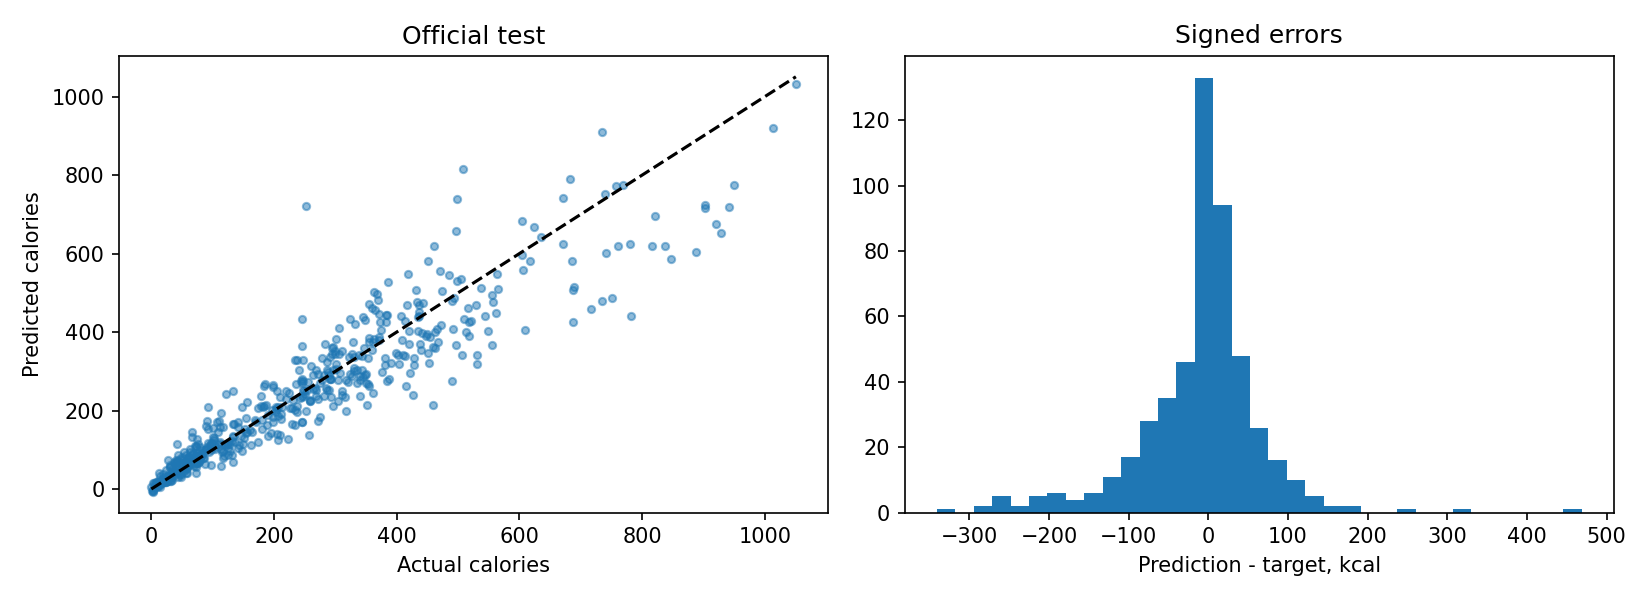

In [27]:
evaluation = evaluate_checkpoint(selected_checkpoint, device="cuda")
metrics = evaluation["metrics"]
predictions = evaluation["predictions"]
report_dir = Path(evaluation["report_dir"])
display(pd.DataFrame([metrics]))
status = "достигнут" if metrics["target_met"] else "не достигнут"
display(Markdown(f"**Test MAE = {metrics['mae']:.3f} ккал. Порог < 50 {status}.**"))
display(DisplayImage(filename=str(report_dir / "test_diagnostics.png"), width=1000))

## 12. Анализ пяти крупнейших ошибок

Отсортирую тестовые блюда по абсолютной ошибке. Для пяти самых сложных примеров покажу фотографию, состав, истинную калорийность и прогноз.

Для объяснения ошибок дополнительно посмотрю на массу порции и частоту ингредиентов в train. Сама основная модель массу не использует. Эти признаки позволяют сформулировать гипотезы, но не доказывают причину ошибки.

,dish_id,ingredients_text,total_mass,total_calories,prediction,abs_error
276,dish_1566501575,brownies,54.0,251.693985,720.343994,468.650009
298,dish_1558549806,"almonds, spinach (raw), white rice",203.0,781.958008,441.240051,340.717957
170,dish_1566501594,brownies,109.0,508.048981,815.243286,307.194305
13,dish_1558720236,"almonds, apple, carrot, cauliflower",407.0,887.823059,603.270020,284.553040
86,dish_1566328805,"cherry tomatoes, chicken, pineapple, pizza",488.0,927.809998,652.570557,275.239441


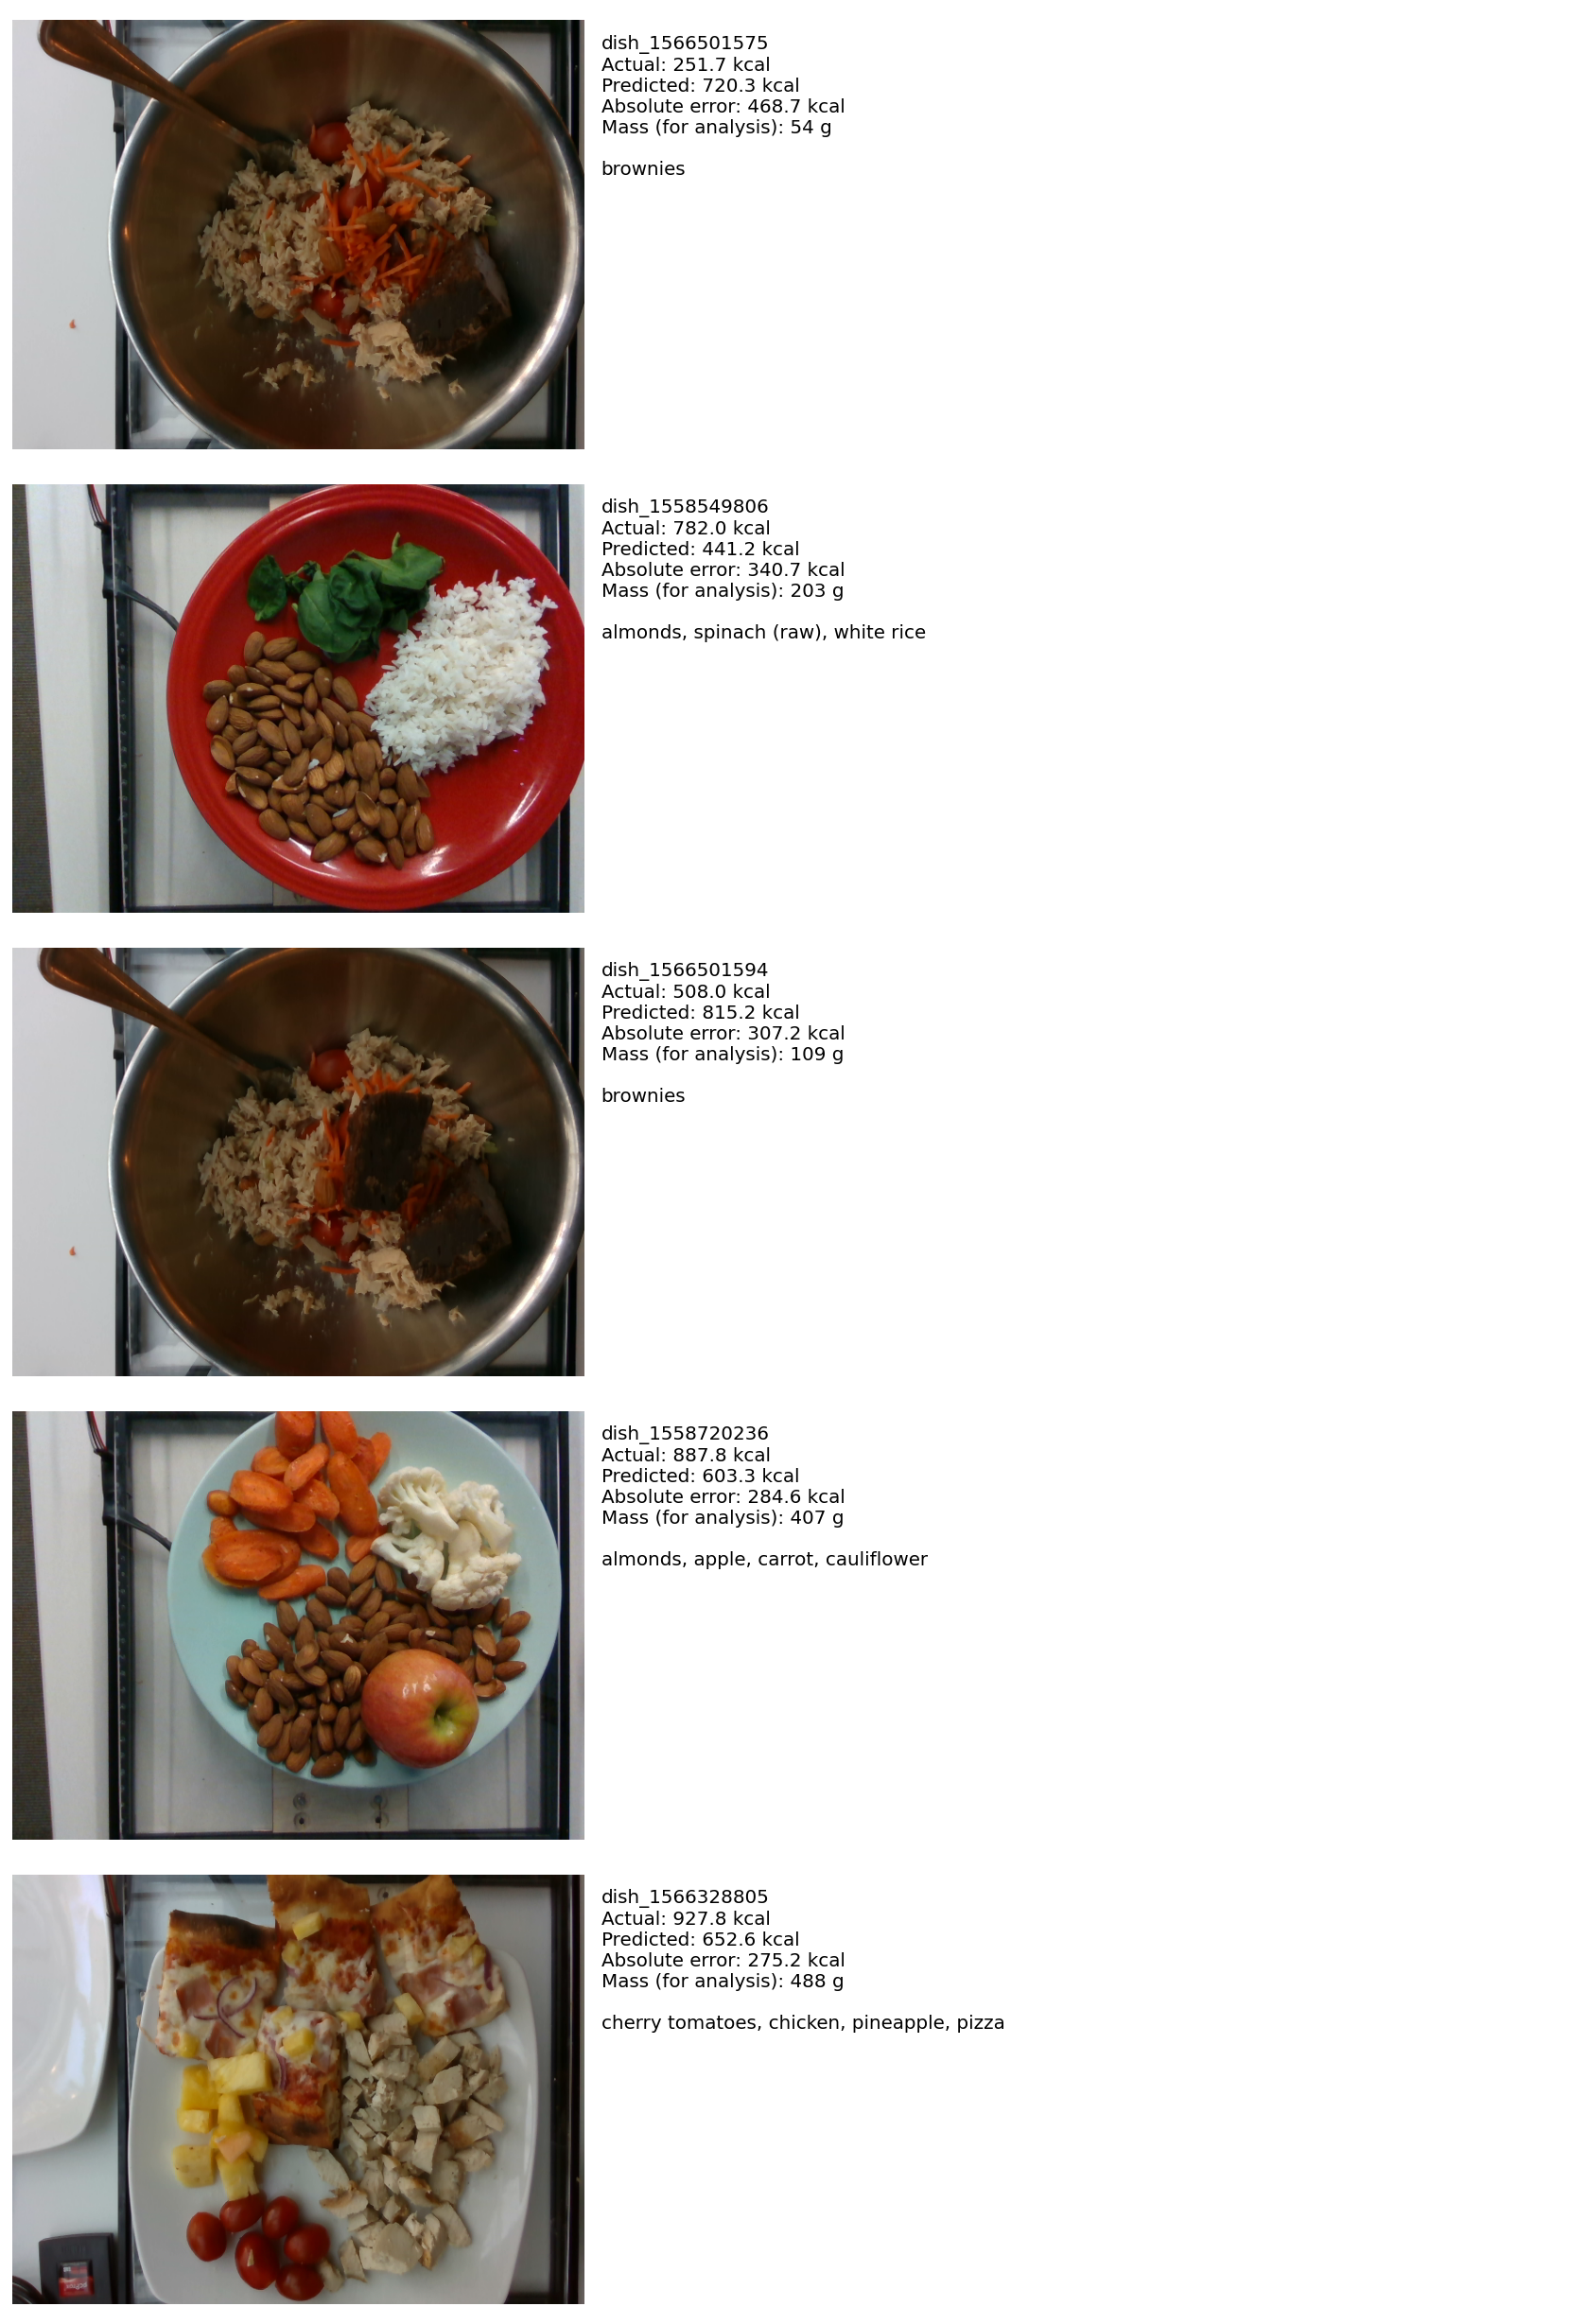

# Пять крупнейших ошибок

Факты вычислены из данных; причины ниже — гипотезы.

## dish_1566501575

Ошибка 468.7 ккал; масса 54 г; ингредиентов 1.

Истина: 251.7; прогноз: 720.3 ккал.

Ингредиенты: brownies.

Гипотезы: Модель не знает массу порции и граммовки отдельных ингредиентов.

Визуальные наблюдения: пока не добавлены.

## dish_1558549806

Ошибка 340.7 ккал; масса 203 г; ингредиентов 3. Калорийность выше 95-го перцентиля train (645.7 ккал).

Истина: 782.0; прогноз: 441.2 ккал.

Ингредиенты: almonds, spinach (raw), white rice.

Гипотезы: Модель могла недообучиться на редких высококалорийных порциях. Модель не знает массу порции и граммовки отдельных ингредиентов.

Визуальные наблюдения: пока не добавлены.

## dish_1566501594

Ошибка 307.2 ккал; масса 109 г; ингредиентов 1.

Истина: 508.0; прогноз: 815.2 ккал.

Ингредиенты: brownies.

Гипотезы: Модель не знает массу порции и граммовки отдельных ингредиентов.

Визуальные наблюдения: пока не добавлены.

## dish_1558720236

Ошибка 284.6 ккал; масса 407 г; ингредиентов 4. Калорийность выше 95-го перцентиля train (645.7 ккал).

Истина: 887.8; прогноз: 603.3 ккал.

Ингредиенты: almonds, apple, carrot, cauliflower.

Гипотезы: Модель могла недообучиться на редких высококалорийных порциях. Модель не знает массу порции и граммовки отдельных ингредиентов.

Визуальные наблюдения: пока не добавлены.

## dish_1566328805

Ошибка 275.2 ккал; масса 488 г; ингредиентов 4. Калорийность выше 95-го перцентиля train (645.7 ккал).

Истина: 927.8; прогноз: 652.6 ккал.

Ингредиенты: cherry tomatoes, chicken, pineapple, pizza.

Гипотезы: Модель могла недообучиться на редких высококалорийных порциях. Модель не знает массу порции и граммовки отдельных ингредиентов.

Визуальные наблюдения: пока не добавлены.


In [28]:
display(predictions.nlargest(5, "abs_error")[["dish_id", "ingredients_text", "total_mass",
                                                  "total_calories", "prediction", "abs_error"]])
display(DisplayImage(filename=str(report_dir / "top5_errors.png"), width=1000))
display(Markdown((report_dir / "ERROR_ANALYSIS.md").read_text(encoding="utf-8")))

## 13. Предсказание для одного блюда

Отдельно проверю загрузку сохраненной модели и прогноз одного блюда. В модель передаются фотография и названия ингредиентов. Сравню результат с прогнозом того же блюда при пакетной обработке.

In [29]:
predictor = load_predictor(selected_checkpoint, device="cuda")
example = splits["test"].iloc[0]
single_prediction = predict_one(predictor, example.image_path, example.ingredient_names)
batch_prediction = predictions.set_index("dish_id").loc[example.dish_id, "prediction"]
print("Блюдо:", example.dish_id)
print("Ингредиенты:", example.ingredients_text)
print(f"Прогноз одного блюда: {single_prediction:.2f}; пакетный прогноз: {batch_prediction:.2f} ккал")
del predictor
torch.cuda.empty_cache()

Блюдо: dish_1561662216
Ингредиенты: apple, bok choy, brown rice, garlic, lemon juice, millet, mixed greens, olive oil, onions, parsley, pepper, pork, salt, soy sauce, sugar, vinegar, white rice
Прогноз одного блюда: 382.59; пакетный прогноз: 382.60 ккал


## 14. Итоговая оценка и сохранение модели

В проекте обучена модель для предсказания калорийности блюда по фотографии и списку ингредиентов. Для обработки изображений использовалась ResNet18, для текста — DistilBERT. Масса порции в качестве признака не использовалась.

Лучший checkpoint выбран по минимальному MAE на валидационной выборке, полученному на 24-й эпохе. Значение MAE составило 42,67 ккал. Для сравнения, baseline TF-IDF + Ridge на той же выборке показал MAE 93,73 ккал. Таким образом, выбранная нейросеть снизила ошибку примерно на 54,5%.

На тестовой выборке из 507 блюд модель получила MAE 49,743 ккал. Целевое требование MAE < 50 выполнено. RMSE составил 77,77 ккал, R² — 0,8655. Медианная абсолютная ошибка равна 29,90 ккал, поэтому примерно для половины блюд предсказание отличается от фактической калорийности не более чем на 30 ккал.

При этом качество неодинаково для всех примеров: 90-й процентиль абсолютной ошибки составляет 118,61 ккал. Средняя знаковая ошибка равна −10,78 ккал, что указывает на небольшое занижение калорийности в среднем. Также получены четыре отрицательных предсказания — физически некорректных значения, возможных при использовании линейного выходного слоя.

Цель по метрике достигнута, однако результат близок к пороговому значению. Для дальнейшего улучшения модели стоит исследовать блюда с наибольшими ошибками и проверить устойчивость качества при другом разбиении обучающей выборки.

In [30]:
display(Markdown((report_dir / "FINAL_REPORT.md").read_text(encoding="utf-8")))
model_archive = export_model(selected_config.run_dir)
print("Архив модели:", model_archive)
print("Папка с метриками и графиками:", report_dir)

# Финальная оценка

Входы: фото + ингредиенты.

Модель выбрана по validation, эпоха 24. Официальный test: 507 блюд.

MAE = **49.743 ккал**, RMSE = 77.773 ккал.

Порог MAE < 50 ккал **достигнут**.

Крупнейшие ошибки приведены в ERROR_ANALYSIS.md и на рисунке top5_errors.png.

Test использован после выбора модели по validation.


Model bundle: C:\ml_projects_mifi\calorie_prediction\artifacts\main_model.zip
SHA256: 1a03aa10c8f40cedbcaafe5fe18868593b351e675c69c69b0a3810b27e5e7570
Архив модели: C:\ml_projects_mifi\calorie_prediction\artifacts\main_model.zip
Папка с метриками и графиками: C:\ml_projects_mifi\calorie_prediction\reports\main
